In [1]:
from pathlib import Path
import pandas as pd
import networkx as nx

# Find the project folder
ROOT = Path.cwd()

if not (ROOT / "data" / "processed").is_dir():
    ROOT = ROOT.parent

PROCESSED = ROOT / "data" / "processed"

# Load the files you saved on Day 1
legs = pd.read_csv(PROCESSED / "legs.csv")
lanes = pd.read_csv(PROCESSED / "lanes.csv")

print("Legs shape:", legs.shape)
print("Lanes shape:", lanes.shape)

Legs shape: (26369, 14)
Lanes shape: (2783, 10)


In [2]:
print("NETWORK SIZE AT DIFFERENT TRIP THRESHOLDS\n")

for threshold in [1, 5, 10, 30]:

    # Keep lanes with at least this many distinct trips
    selected = lanes[lanes["trip_count"] >= threshold]

    # Build the directed network: source → destination
    graph = nx.from_pandas_edgelist(
        selected,
        source="source_center",
        target="destination_center",
        create_using=nx.DiGraph()
    )

    hub_count = graph.number_of_nodes()
    lane_count = graph.number_of_edges()

    if hub_count > 0:
        largest_weak = max(
            nx.weakly_connected_components(graph),
            key=len
        )

        largest_strong = max(
            nx.strongly_connected_components(graph),
            key=len
        )

        weak_percent = 100 * len(largest_weak) / hub_count
        strong_percent = 100 * len(largest_strong) / hub_count
    else:
        weak_percent = 0
        strong_percent = 0

    print(f"Minimum trips per lane: {threshold}")
    print(f"  Hubs: {hub_count}")
    print(f"  Directed lanes: {lane_count}")
    print(f"  Largest weakly connected group: {weak_percent:.1f}%")
    print(f"  Largest strongly connected group: {strong_percent:.1f}%")
    print()

NETWORK SIZE AT DIFFERENT TRIP THRESHOLDS

Minimum trips per lane: 1
  Hubs: 1657
  Directed lanes: 2783
  Largest weakly connected group: 81.7%
  Largest strongly connected group: 54.9%

Minimum trips per lane: 5
  Hubs: 1288
  Directed lanes: 1631
  Largest weakly connected group: 69.9%
  Largest strongly connected group: 35.5%

Minimum trips per lane: 10
  Hubs: 958
  Directed lanes: 1130
  Largest weakly connected group: 60.9%
  Largest strongly connected group: 25.6%

Minimum trips per lane: 30
  Hubs: 79
  Directed lanes: 99
  Largest weakly connected group: 64.6%
  Largest strongly connected group: 24.1%



In [3]:
# Keep one row per trip
trips = legs[["trip_uuid", "trip_creation_time"]].drop_duplicates(
    subset="trip_uuid"
).copy()

# Convert timestamps to dates
trips["trip_creation_time"] = pd.to_datetime(
    trips["trip_creation_time"],
    errors="coerce"
)

trips["trip_date"] = trips["trip_creation_time"].dt.date

# Count distinct trips created on each date
trips_per_day = trips.groupby("trip_date")["trip_uuid"].nunique()

print("Trip date range:")
print(trips["trip_creation_time"].min(), "to",
      trips["trip_creation_time"].max())

print("\nTrips per day:")
print(trips_per_day.to_string())

Trip date range:
2018-09-12 00:00:16.535741 to 2018-10-03 23:59:42.701692

Trips per day:
trip_date
2018-09-12    747
2018-09-13    750
2018-09-14    712
2018-09-15    783
2018-09-16    616
2018-09-17    722
2018-09-18    791
2018-09-19    676
2018-09-20    704
2018-09-21    740
2018-09-22    740
2018-09-23    631
2018-09-24    660
2018-09-25    697
2018-09-26    685
2018-09-27    652
2018-09-28    608
2018-09-29    607
2018-09-30    508
2018-10-01    605
2018-10-02    552
2018-10-03    631


In [4]:
# Use lanes with at least 5 distinct trips
selected = lanes[lanes["trip_count"] >= 5]

# Create the directed network
graph_5 = nx.from_pandas_edgelist(
    selected,
    source="source_center",
    target="destination_center",
    create_using=nx.DiGraph()
)

print("Calculating hub importance... This may take a little time.")

# Calculate betweenness using the number of lanes in a path
betweenness = nx.betweenness_centrality(graph_5)

# Create a table of hub statistics
hub_stats = pd.DataFrame({
    "hub": list(graph_5.nodes()),
    "incoming_lanes": [graph_5.in_degree(h) for h in graph_5.nodes()],
    "outgoing_lanes": [graph_5.out_degree(h) for h in graph_5.nodes()],
    "betweenness": [betweenness[h] for h in graph_5.nodes()]
})

hub_stats["total_lanes"] = (
    hub_stats["incoming_lanes"] + hub_stats["outgoing_lanes"]
)

hub_stats = hub_stats.sort_values(
    "betweenness",
    ascending=False
)

print("Top 10 hubs by betweenness:")
display(hub_stats.head(10))

Calculating hub importance... This may take a little time.
Top 10 hubs by betweenness:


,hub,incoming_lanes,outgoing_lanes,betweenness,total_lanes
7,IND000000ACB,36,41,0.147420,77
0,IND562132AAA,29,27,0.082477,56
48,IND501359AAE,27,22,0.060067,49
4,IND421302AAG,21,26,0.040760,47
27,IND712311AAA,14,17,0.040064,31
3,IND411033AAA,16,17,0.038834,33
9,IND131028AAB,15,11,0.031504,26
13,IND160002AAC,21,19,0.030753,40
16,IND600056AAB,13,16,0.027240,29
42,IND382430AAB,14,12,0.026614,26


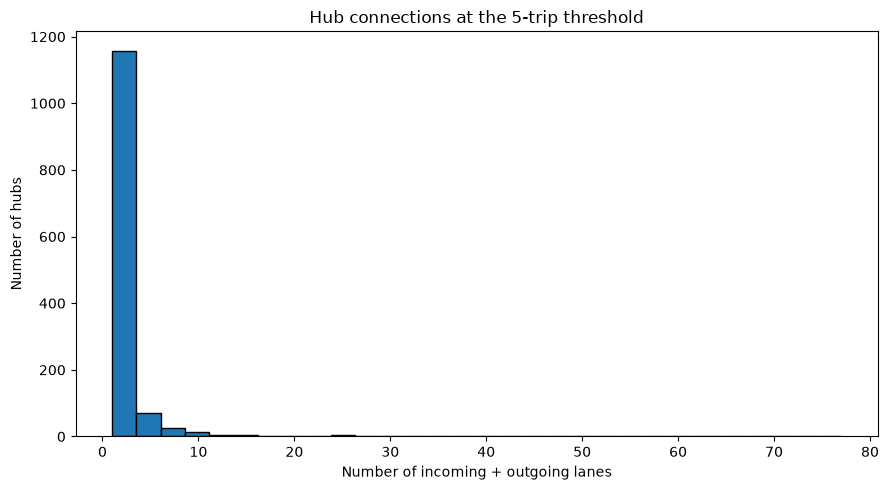

Saved: c:\local\supplyshield\data\processed\hub_stats.csv
Saved: c:\local\supplyshield\docs\hub_degree_hist.png

Top 10 hubs with names:


,hub,name,incoming_lanes,outgoing_lanes,betweenness
0,IND000000ACB,Gurgaon_Bilaspur_HB (Haryana),36,41,0.147420
1,IND562132AAA,Bangalore_Nelmngla_H (Karnataka),29,27,0.082477
2,IND501359AAE,Hyderabad_Shamshbd_H (Telangana),27,22,0.060067
3,IND421302AAG,Bhiwandi_Mankoli_HB (Maharashtra),21,26,0.040760
4,IND712311AAA,Kolkata_Dankuni_HB (West Bengal),14,17,0.040064
5,IND411033AAA,Pune_Tathawde_H (Maharashtra),16,17,0.038834
6,IND131028AAB,Sonipat_Kundli_H (Haryana),15,11,0.031504
7,IND160002AAC,Chandigarh_Mehmdpur_H (Punjab),21,19,0.030753
8,IND600056AAB,MAA_Poonamallee_HB (Tamil Nadu),13,16,0.027240
9,IND382430AAB,Ahmedabad_East_H_1 (Gujarat),14,12,0.026614


In [5]:
import matplotlib.pyplot as plt

# Create a table mapping hub IDs to names
sources = legs[["source_center", "source_name"]].rename(
    columns={"source_center": "hub", "source_name": "name"}
)

destinations = legs[["destination_center", "destination_name"]].rename(
    columns={"destination_center": "hub", "destination_name": "name"}
)

hub_names = pd.concat([sources, destinations], ignore_index=True)

# Prefer a non-empty name when one is available
hub_names = hub_names.dropna(subset=["name"]).drop_duplicates(
    subset="hub"
)

# Add names to the hub statistics
hub_stats = hub_stats.merge(hub_names, on="hub", how="left")

# Save the hub statistics
hub_stats.to_csv(PROCESSED / "hub_stats.csv", index=False)

# Create and save the degree histogram
DOCS = ROOT / "docs"
DOCS.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 5))
plt.hist(hub_stats["total_lanes"], bins=30, edgecolor="black")
plt.xlabel("Number of incoming + outgoing lanes")
plt.ylabel("Number of hubs")
plt.title("Hub connections at the 5-trip threshold")
plt.tight_layout()
plt.savefig(DOCS / "hub_degree_hist.png", dpi=150)
plt.show()

print("Saved:", PROCESSED / "hub_stats.csv")
print("Saved:", DOCS / "hub_degree_hist.png")

print("\nTop 10 hubs with names:")
display(
    hub_stats[
        ["hub", "name", "incoming_lanes", "outgoing_lanes", "betweenness"]
    ].head(10)
)

In [6]:
# Make a copy so the saved hub statistics remain available
hubs = hub_stats[["hub", "name"]].copy()

# Extract the first part of the name as a city guess
hubs["city"] = (
    hubs["name"]
    .str.split("_")
    .str[0]
    .str.strip()
)

# Extract the state from parentheses
hubs["state"] = (
    hubs["name"]
    .str.extract(r"\(([^)]+)\)", expand=False)
    .str.strip()
)

# Extract six digits after IND as a possible pincode
hubs["pincode_guess"] = (
    hubs["hub"]
    .str.extract(r"^IND(\d{6})", expand=False)
)

print("Total hubs:", len(hubs))
print("Missing names:", hubs["name"].isna().sum())
print("Missing city guesses:", hubs["city"].isna().sum())
print("Missing states:", hubs["state"].isna().sum())
print("IDs with six digits after IND:",
      hubs["pincode_guess"].notna().sum())

display(hubs.head(10))

Total hubs: 1288
Missing names: 6
Missing city guesses: 6
Missing states: 6
IDs with six digits after IND: 1287


,hub,name,city,state,pincode_guess
0,IND000000ACB,Gurgaon_Bilaspur_HB (Haryana),Gurgaon,Haryana,000000
1,IND562132AAA,Bangalore_Nelmngla_H (Karnataka),Bangalore,Karnataka,562132
2,IND501359AAE,Hyderabad_Shamshbd_H (Telangana),Hyderabad,Telangana,501359
3,IND421302AAG,Bhiwandi_Mankoli_HB (Maharashtra),Bhiwandi,Maharashtra,421302
4,IND712311AAA,Kolkata_Dankuni_HB (West Bengal),Kolkata,West Bengal,712311
5,IND411033AAA,Pune_Tathawde_H (Maharashtra),Pune,Maharashtra,411033
6,IND131028AAB,Sonipat_Kundli_H (Haryana),Sonipat,Haryana,131028
7,IND160002AAC,Chandigarh_Mehmdpur_H (Punjab),Chandigarh,Punjab,160002
8,IND600056AAB,MAA_Poonamallee_HB (Tamil Nadu),MAA,Tamil Nadu,600056
9,IND382430AAB,Ahmedabad_East_H_1 (Gujarat),Ahmedabad,Gujarat,382430


In [7]:
print("Sample hub locations:")
display(
    hubs[["hub", "name", "city", "state", "pincode_guess"]]
    .head(20)
)

print("\nHubs with missing names:")
display(hubs[hubs["name"].isna()])

Sample hub locations:


,hub,name,city,state,pincode_guess
0,IND000000ACB,Gurgaon_Bilaspur_HB (Haryana),Gurgaon,Haryana,000000
1,IND562132AAA,Bangalore_Nelmngla_H (Karnataka),Bangalore,Karnataka,562132
2,IND501359AAE,Hyderabad_Shamshbd_H (Telangana),Hyderabad,Telangana,501359
3,IND421302AAG,Bhiwandi_Mankoli_HB (Maharashtra),Bhiwandi,Maharashtra,421302
4,IND712311AAA,Kolkata_Dankuni_HB (West Bengal),Kolkata,West Bengal,712311
5,IND411033AAA,Pune_Tathawde_H (Maharashtra),Pune,Maharashtra,411033
6,IND131028AAB,Sonipat_Kundli_H (Haryana),Sonipat,Haryana,131028
7,IND160002AAC,Chandigarh_Mehmdpur_H (Punjab),Chandigarh,Punjab,160002
8,IND600056AAB,MAA_Poonamallee_HB (Tamil Nadu),MAA,Tamil Nadu,600056
9,IND382430AAB,Ahmedabad_East_H_1 (Gujarat),Ahmedabad,Gujarat,382430



Hubs with missing names:


,hub,name,city,state,pincode_guess
56,IND282002AAD,NaN,NaN,NaN,282002
423,IND577116AAA,NaN,NaN,NaN,577116
499,IND342902A1B,NaN,NaN,NaN,342902
787,IND126116AAA,NaN,NaN,NaN,126116
1207,IND852118A1B,NaN,NaN,NaN,852118
1247,IND509103AAC,NaN,NaN,NaN,509103


In [8]:
import requests

url = "https://geocoding-api.open-meteo.com/v1/search"

params = {
    "name": "Gurgaon",
    "count": 5,
    "language": "en",
    "format": "json",
    "countryCode": "IN"
}

response = requests.get(url, params=params, timeout=20)
response.raise_for_status()

results = response.json().get("results", [])

print("Number of matches:", len(results))

for place in results:
    print(
        place.get("name"),
        "| State:", place.get("admin1"),
        "| Latitude:", place.get("latitude"),
        "| Longitude:", place.get("longitude")
    )

Number of matches: 5
Gurgaon | State: Maharashtra | Latitude: 19.34249 | Longitude: 77.26757
Gurgaon | State: Uttar Pradesh | Latitude: 27.99723 | Longitude: 79.23053
Gurgaon | State: Uttar Pradesh | Latitude: 27.69366 | Longitude: 79.67539
Gūrgaon | State: Uttar Pradesh | Latitude: 28.43549 | Longitude: 79.13486
Gurgaon | State: Uttar Pradesh | Latitude: 26.28087 | Longitude: 79.82833


In [9]:
params = {
    "name": "Gurugram, Haryana",
    "count": 10,
    "language": "en",
    "format": "json",
    "countryCode": "IN"
}

response = requests.get(url, params=params, timeout=20)
response.raise_for_status()

results = response.json().get("results", [])

print("Number of matches:", len(results))

for place in results:
    print(
        place.get("name"),
        "| State:", place.get("admin1"),
        "| Latitude:", place.get("latitude"),
        "| Longitude:", place.get("longitude")
    )

Number of matches: 1
Gurugram | State: Haryana | Latitude: 28.4601 | Longitude: 77.02635


In [10]:
# Keep the original city guess and create a search name
hubs["search_city"] = hubs["city"]

# Known name variations from our sample
city_aliases = {
    "Gurgaon": "Gurugram",
    "Bangalore": "Bengaluru",
    "MAA": "Chennai",
}

hubs["search_city"] = hubs["search_city"].replace(city_aliases)

# Open-Meteo may use the current state name
hubs["search_state"] = hubs["state"].replace({
    "Orissa": "Odisha"
})

# Mark the clearly unusable 000000 code
hubs["pincode_candidate"] = hubs["pincode_guess"].where(
    hubs["pincode_guess"] != "000000"
)

print("First 10 hub search names:")
display(
    hubs[
        ["hub", "name", "search_city", "search_state", "pincode_candidate"]
    ].head(10)
)

First 10 hub search names:


,hub,name,search_city,search_state,pincode_candidate
0,IND000000ACB,Gurgaon_Bilaspur_HB (Haryana),Gurugram,Haryana,NaN
1,IND562132AAA,Bangalore_Nelmngla_H (Karnataka),Bengaluru,Karnataka,562132
2,IND501359AAE,Hyderabad_Shamshbd_H (Telangana),Hyderabad,Telangana,501359
3,IND421302AAG,Bhiwandi_Mankoli_HB (Maharashtra),Bhiwandi,Maharashtra,421302
4,IND712311AAA,Kolkata_Dankuni_HB (West Bengal),Kolkata,West Bengal,712311
5,IND411033AAA,Pune_Tathawde_H (Maharashtra),Pune,Maharashtra,411033
6,IND131028AAB,Sonipat_Kundli_H (Haryana),Sonipat,Haryana,131028
7,IND160002AAC,Chandigarh_Mehmdpur_H (Punjab),Chandigarh,Punjab,160002
8,IND600056AAB,MAA_Poonamallee_HB (Tamil Nadu),Chennai,Tamil Nadu,600056
9,IND382430AAB,Ahmedabad_East_H_1 (Gujarat),Ahmedabad,Gujarat,382430


In [11]:
import json
import time
import requests

# Store successful lookups in this file
cache_path = PROCESSED / "geocode_cache.json"

if cache_path.exists():
    with open(cache_path, "r", encoding="utf-8") as file:
        cache = json.load(file)
else:
    cache = {}

url = "https://geocoding-api.open-meteo.com/v1/search"
session = requests.Session()


def normalise(value):
    return str(value).strip().casefold()


def lookup_city(city, state):
    # We need both city and state for a reliable first match
    if pd.isna(city) or pd.isna(state):
        return {"match": "missing_city_or_state"}

    city = str(city).strip()
    state = str(state).strip()

    if len(city) < 2:
        return {"match": "invalid_city"}

    cache_key = f"{city.casefold()}|{state.casefold()}"

    # Reuse a previous successful search
    if cache_key in cache:
        return cache[cache_key]

    try:
        response = session.get(
            url,
            params={
                "name": f"{city}, {state}",
                "count": 20,
                "language": "en",
                "format": "json",
                "countryCode": "IN"
            },
            timeout=20
        )
        response.raise_for_status()
        results = response.json().get("results", [])

    except requests.RequestException as error:
        # Do not cache network errors: a rerun can retry them
        return {
            "match": "request_error",
            "error": str(error)
        }

    # Require both returned city name and state to match.
    # Prefix-only or state-mismatched results are left for review.
    exact = [
        place for place in results
        if normalise(place.get("name", "")) == normalise(city)
        and normalise(place.get("admin1", "")) == normalise(state)
    ]

    if exact:
        place = exact[0]

        result = {
            "match": "city+state",
            "matched_name": place.get("name"),
            "matched_state": place.get("admin1"),
            "latitude": place.get("latitude"),
            "longitude": place.get("longitude"),
        }
    else:
        result = {"match": "no_exact_match"}

    # Save both matches and no-match results after each request
    cache[cache_key] = result

    with open(cache_path, "w", encoding="utf-8") as file:
        json.dump(cache, file, ensure_ascii=False, indent=2)

    # Small pause between new requests
    time.sleep(0.2)

    return result


lookup_results = []

for position, row in enumerate(hubs.itertuples(index=False), start=1):
    result = lookup_city(row.search_city, row.search_state)
    lookup_results.append(result)

    if position % 100 == 0:
        print(f"Processed {position} of {len(hubs)} hubs")

# Add lookup results to the hub table
result_table = pd.DataFrame(lookup_results, index=hubs.index)

# Safe to rerun without creating duplicate result columns
result_columns = [
    "match", "matched_name", "matched_state",
    "latitude", "longitude", "error"
]

hubs = hubs.drop(
    columns=[col for col in result_columns if col in hubs.columns]
)

hubs = pd.concat([hubs, result_table], axis=1)

# Save hub locations and match status
hubs.to_csv(PROCESSED / "hubs.csv", index=False)

print("\nMatch-quality counts:")
print(hubs["match"].value_counts(dropna=False))

print("\nFirst 20 hubs needing review:")
display(
    hubs.loc[
        hubs["match"] != "city+state",
        ["hub", "name", "search_city", "search_state", "match"]
    ].head(20)
)

print("\nSaved:", PROCESSED / "hubs.csv")
print("Cache:", cache_path)

Processed 100 of 1288 hubs
Processed 200 of 1288 hubs
Processed 300 of 1288 hubs
Processed 400 of 1288 hubs
Processed 500 of 1288 hubs
Processed 600 of 1288 hubs
Processed 700 of 1288 hubs
Processed 800 of 1288 hubs
Processed 900 of 1288 hubs
Processed 1000 of 1288 hubs
Processed 1100 of 1288 hubs
Processed 1200 of 1288 hubs

Match-quality counts:
match
city+state               679
no_exact_match           603
missing_city_or_state      6
Name: count, dtype: int64

First 20 hubs needing review:


,hub,name,search_city,search_state,match
6,IND131028AAB,Sonipat_Kundli_H (Haryana),Sonipat,Haryana,no_exact_match
7,IND160002AAC,Chandigarh_Mehmdpur_H (Punjab),Chandigarh,Punjab,no_exact_match
10,IND842001AAA,Muzaffrpur_Bbganj_I (Bihar),Muzaffrpur,Bihar,no_exact_match
16,IND751002AAB,Bhubaneshwar_Hub (Orissa),Bhubaneshwar,Odisha,no_exact_match
17,IND110037AAM,Delhi_Airport_H (Delhi),Delhi,Delhi,no_exact_match
25,IND403726AAA,Goa_Hub (Goa),Goa,Goa,no_exact_match
26,IND575004AAB,Mangalore_Kuntikna_H (Karnataka),Mangalore,Karnataka,no_exact_match
30,IND574202AAA,Puttur_Darbe_DC (Karnataka),Puttur,Karnataka,no_exact_match
31,IND574211AAA,Bantwal_Trmltmpl_D (Karnataka),Bantwal,Karnataka,no_exact_match
33,IND211002AAB,Allahabad_Central_H_1 (Uttar Pradesh),Allahabad,Uttar Pradesh,no_exact_match



Saved: c:\local\supplyshield\data\processed\hubs.csv
Cache: c:\local\supplyshield\data\processed\geocode_cache.json


In [12]:
# Create a copy so the original legs table stays unchanged
distance_analysis = legs.copy()

# Convert the relevant columns to numeric
distance_analysis["osrm_distance_km"] = pd.to_numeric(
    distance_analysis["osrm_distance_km"],
    errors="coerce"
)

distance_analysis["delay_ratio"] = pd.to_numeric(
    distance_analysis["delay_ratio"],
    errors="coerce"
)

# Group journey legs by estimated distance
distance_analysis["distance_bucket"] = pd.cut(
    distance_analysis["osrm_distance_km"],
    bins=[0, 50, 100, 250, 500, float("inf")],
    labels=["0–50 km", "50–100 km", "100–250 km",
            "250–500 km", "500+ km"],
    include_lowest=True
)

# Summarize delay ratios for each distance group
distance_summary = (
    distance_analysis
    .groupby("distance_bucket", observed=False)["delay_ratio"]
    .agg(
        number_of_legs="count",
        median_ratio="median",
        mean_ratio="mean"
    )
    .reset_index()
)

print("Delay ratio by distance bucket:")
display(distance_summary)

print(
    "Legs without a distance bucket:",
    distance_analysis["distance_bucket"].isna().sum()
)

Delay ratio by distance bucket:


,distance_bucket,number_of_legs,median_ratio,mean_ratio
0,0–50 km,14830,2.071429,2.732065
1,50–100 km,5910,1.916667,2.333373
2,100–250 km,3445,1.995305,2.392963
3,250–500 km,1119,1.968037,2.069095
4,500+ km,1065,1.950904,2.009215


Legs without a distance bucket: 0


In [13]:
import pandas as pd
from pathlib import Path

# Find your SupplyShield project folder
ROOT = Path.cwd()

if not (ROOT / "data" / "raw").is_dir():
    ROOT = ROOT.parent

# Load the Olist orders dataset
o = pd.read_csv(ROOT / "data" / "raw" / "olist_orders_dataset.csv")

# Convert the delivery and estimated dates
date_columns = [
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    o[col] = pd.to_datetime(o[col], errors="coerce")

# Keep only orders with both dates available
o = o.dropna(subset=date_columns).copy()

# Count deliveries after the estimated delivery timestamp
total_orders = len(o)

late_orders = (
    o["order_delivered_customer_date"]
    > o["order_estimated_delivery_date"]
).sum()

late_percentage = (late_orders / total_orders) * 100

print("Usable orders:", total_orders)
print("Late orders:", late_orders)
print(f"Late delivery percentage: {late_percentage:.2f}%")

Usable orders: 96476
Late orders: 7827
Late delivery percentage: 8.11%


In [14]:
import pandas as pd

# Load the location and network results saved on Day 2
hubs = pd.read_csv(PROCESSED / "hubs.csv")
hub_stats = pd.read_csv(PROCESSED / "hub_stats.csv")

# Join location results with hub importance
hub_review = hubs.merge(
    hub_stats[["hub", "betweenness", "total_lanes"]],
    on="hub",
    how="left"
)

# Find hubs that did not get an exact city-and-state match
unmatched = hub_review[
    hub_review["match"] != "city+state"
].copy()

# Show the most important unmatched hubs first
unmatched = unmatched.sort_values(
    "betweenness",
    ascending=False
)

print("Total hubs:", len(hub_review))
print("Hubs needing location review:", len(unmatched))

print("\nTop 20 unmatched hubs by betweenness:")
display(
    unmatched[
        [
            "hub",
            "name",
            "search_city",
            "search_state",
            "match",
            "betweenness",
            "total_lanes"
        ]
    ].head(20)
)

Total hubs: 1288
Hubs needing location review: 609

Top 20 unmatched hubs by betweenness:


,hub,name,search_city,search_state,match,betweenness,total_lanes
6,IND131028AAB,Sonipat_Kundli_H (Haryana),Sonipat,Haryana,no_exact_match,0.031504,26
7,IND160002AAC,Chandigarh_Mehmdpur_H (Punjab),Chandigarh,Punjab,no_exact_match,0.030753,40
10,IND842001AAA,Muzaffrpur_Bbganj_I (Bihar),Muzaffrpur,Bihar,no_exact_match,0.022437,20
16,IND751002AAB,Bhubaneshwar_Hub (Orissa),Bhubaneshwar,Odisha,no_exact_match,0.012462,11
17,IND110037AAM,Delhi_Airport_H (Delhi),Delhi,Delhi,no_exact_match,0.011774,25
25,IND403726AAA,Goa_Hub (Goa),Goa,Goa,no_exact_match,0.008637,6
26,IND575004AAB,Mangalore_Kuntikna_H (Karnataka),Mangalore,Karnataka,no_exact_match,0.008243,5
30,IND574202AAA,Puttur_Darbe_DC (Karnataka),Puttur,Karnataka,no_exact_match,0.007855,2
31,IND574211AAA,Bantwal_Trmltmpl_D (Karnataka),Bantwal,Karnataka,no_exact_match,0.007851,2
33,IND211002AAB,Allahabad_Central_H_1 (Uttar Pradesh),Allahabad,Uttar Pradesh,no_exact_match,0.007475,9


In [15]:
import requests

url = "https://geocoding-api.open-meteo.com/v1/search"

# Search city names without adding the state to the query
test_cities = ["Sonipat", "Chandigarh"]

for city in test_cities:
    print(f"\nResults for: {city}")

    try:
        response = requests.get(
            url,
            params={
                "name": city,
                "count": 10,
                "language": "en",
                "format": "json",
                "countryCode": "IN"
            },
            timeout=20
        )
        response.raise_for_status()

        results = response.json().get("results", [])

        if not results:
            print("No results found.")

        for place in results:
            print(
                "Name:", place.get("name"),
                "| State:", place.get("admin1"),
                "| Latitude:", place.get("latitude"),
                "| Longitude:", place.get("longitude")
            )

    except requests.RequestException as error:
        print("Request failed:", error)


Results for: Sonipat
Name: Sonīpat | State: Haryana | Latitude: 28.99478 | Longitude: 77.01937

Results for: Chandigarh
Name: Chandigarh | State: Chandigarh | Latitude: 30.73629 | Longitude: 76.7884
Name: Chandigarh | State: Tripura | Latitude: 23.50211 | Longitude: 91.33715
Name: Chandīgarh | State: Haryana | Latitude: 30.72778 | Longitude: 76.77778
Name: Chandigarhi | State: Uttar Pradesh | Latitude: 26.43376 | Longitude: 80.78706
Name: Chandigarh International Airport | State: Chandigarh | Latitude: 30.6735 | Longitude: 76.7885


In [16]:
# Inspect the two hubs before choosing approximate locations
hub_ids = ["IND131028AAB", "IND160002AAC"]

display(
    hubs.loc[
        hubs["hub"].isin(hub_ids),
        [
            "hub",
            "name",
            "search_city",
            "search_state",
            "pincode_candidate",
            "match",
            "latitude",
            "longitude"
        ]
    ]
)

,hub,name,search_city,search_state,pincode_candidate,match,latitude,longitude
6,IND131028AAB,Sonipat_Kundli_H (Haryana),Sonipat,Haryana,131028.0,no_exact_match,NaN,NaN
7,IND160002AAC,Chandigarh_Mehmdpur_H (Punjab),Chandigarh,Punjab,160002.0,no_exact_match,NaN,NaN


In [17]:
import unicodedata

def remove_accents(text):
    # Convert accented letters to their unaccented form
    text = unicodedata.normalize("NFKD", str(text))
    return "".join(
        char for char in text
        if not unicodedata.combining(char)
    ).casefold().strip()

dataset_name = "Sonipat"
api_name = "Sonīpat"

print("Dataset city:", dataset_name)
print("API city:", api_name)

print("\nAfter removing accents:")
print("Dataset:", remove_accents(dataset_name))
print("API:    ", remove_accents(api_name))

print("\nNames match:", remove_accents(dataset_name) == remove_accents(api_name))

Dataset city: Sonipat
API city: Sonīpat

After removing accents:
Dataset: sonipat
API:     sonipat

Names match: True


In [18]:
import requests
import unicodedata
import pandas as pd

def normalise_name(value):
    text = unicodedata.normalize("NFKD", str(value))
    text = "".join(
        char for char in text
        if not unicodedata.combining(char)
    )
    return text.casefold().strip()

url = "https://geocoding-api.open-meteo.com/v1/search"

# Test the 20 most important unmatched hubs
test_hubs = unmatched.head(20)
test_results = []

for row in test_hubs.itertuples(index=False):
    city = row.search_city
    state = row.search_state

    result = {
        "hub": row.hub,
        "search_city": city,
        "search_state": state,
        "result": "not checked",
        "matched_name": None,
        "matched_state": None,
        "latitude": None,
        "longitude": None
    }

    if pd.isna(city) or pd.isna(state):
        result["result"] = "missing city or state"
        test_results.append(result)
        continue

    try:
        response = requests.get(
            url,
            params={
                "name": city,
                "count": 20,
                "language": "en",
                "format": "json",
                "countryCode": "IN"
            },
            timeout=20
        )
        response.raise_for_status()

        places = response.json().get("results", [])

        matches = [
            place for place in places
            if normalise_name(place.get("name", "")) == normalise_name(city)
            and normalise_name(place.get("admin1", "")) == normalise_name(state)
        ]

        if len(matches) == 1:
            place = matches[0]
            result.update({
                "result": "city and state match",
                "matched_name": place.get("name"),
                "matched_state": place.get("admin1"),
                "latitude": place.get("latitude"),
                "longitude": place.get("longitude")
            })
        elif len(matches) > 1:
            result["result"] = "multiple matches: review"
        else:
            result["result"] = "no match: review"

    except requests.RequestException as error:
        result["result"] = f"request error: {error}"

    test_results.append(result)

test_results = pd.DataFrame(test_results)

print("Test result counts:")
print(test_results["result"].value_counts())

display(test_results)

Test result counts:
result
no match: review            14
multiple matches: review     3
city and state match         2
missing city or state        1
Name: count, dtype: int64


,hub,search_city,search_state,result,matched_name,matched_state,latitude,longitude
0,IND131028AAB,Sonipat,Haryana,city and state match,Sonīpat,Haryana,28.99478,77.01937
1,IND160002AAC,Chandigarh,Punjab,no match: review,NaN,NaN,NaN,NaN
2,IND842001AAA,Muzaffrpur,Bihar,no match: review,NaN,NaN,NaN,NaN
3,IND751002AAB,Bhubaneshwar,Odisha,no match: review,NaN,NaN,NaN,NaN
4,IND110037AAM,Delhi,Delhi,no match: review,NaN,NaN,NaN,NaN
5,IND403726AAA,Goa,Goa,no match: review,NaN,NaN,NaN,NaN
6,IND575004AAB,Mangalore,Karnataka,no match: review,NaN,NaN,NaN,NaN
7,IND574202AAA,Puttur,Karnataka,multiple matches: review,NaN,NaN,NaN,NaN
8,IND574211AAA,Bantwal,Karnataka,no match: review,NaN,NaN,NaN,NaN
9,IND211002AAB,Allahabad,Uttar Pradesh,multiple matches: review,NaN,NaN,NaN,NaN


In [19]:
# Hubs that already have saved city-and-state matches
matched_hubs = set(
    hubs.loc[
        (hubs["match"] == "city+state")
        & hubs["latitude"].notna()
        & hubs["longitude"].notna(),
        "hub"
    ]
)

# Check which legs have locations at their source and destination
source_matched = legs["source_center"].isin(matched_hubs)
destination_matched = legs["destination_center"].isin(matched_hubs)

print("Total journey legs:", len(legs))
print("Hubs with saved coordinates:", len(matched_hubs))

print(
    "\nLegs with a matched source hub:",
    source_matched.sum(),
    f"({source_matched.mean() * 100:.2f}%)"
)

print(
    "Legs with a matched destination hub:",
    destination_matched.sum(),
    f"({destination_matched.mean() * 100:.2f}%)"
)

print(
    "Legs with both hubs matched:",
    (source_matched & destination_matched).sum(),
    f"({(source_matched & destination_matched).mean() * 100:.2f}%)"
)

Total journey legs: 26369
Hubs with saved coordinates: 679

Legs with a matched source hub: 16275 (61.72%)
Legs with a matched destination hub: 15974 (60.58%)
Legs with both hubs matched: 10525 (39.91%)


In [20]:
import requests
import pandas as pd

# Select one hub that already has saved coordinates
matched = hubs[
    (hubs["match"] == "city+state")
    & hubs["latitude"].notna()
    & hubs["longitude"].notna()
]

hub = matched.iloc[0]

print("Testing hub:", hub["name"])
print("Coordinates:", hub["latitude"], hub["longitude"])

# Request historical daily weather for the Delhivery data period
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": hub["latitude"],
    "longitude": hub["longitude"],
    "start_date": "2018-09-12",
    "end_date": "2018-10-03",
    "daily": "precipitation_sum",
    "timezone": "Asia/Kolkata"
}

try:
    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()

    weather_data = response.json()

    weather = pd.DataFrame(weather_data["daily"])
    weather = weather.rename(columns={
        "time": "date",
        "precipitation_sum": "rain_mm"
    })

    print("\nDaily rainfall for the selected location:")
    display(weather)

    print("\nNumber of days received:", len(weather))

except requests.RequestException as error:
    print("Weather request failed:", error)

Testing hub: Gurgaon_Bilaspur_HB (Haryana)
Coordinates: 28.4601 77.02635

Daily rainfall for the selected location:


,date,rain_mm
0,2018-09-12,0.2
1,2018-09-13,0.0
2,2018-09-14,0.0
3,2018-09-15,0.0
4,2018-09-16,0.0
5,2018-09-17,0.1
6,2018-09-18,0.0
7,2018-09-19,0.0
8,2018-09-20,0.0
9,2018-09-21,2.0



Number of days received: 22


In [21]:
# Select legs starting from the hub used in the weather test
hub_legs = legs[
    legs["source_center"] == hub["hub"]
].copy()

# Get the date on which each journey leg started
hub_legs["leg_start_date"] = pd.to_datetime(
    hub_legs["od_start_time"],
    errors="coerce"
).dt.strftime("%Y-%m-%d")

# Join weather by the leg start date
hub_weather_test = hub_legs.merge(
    weather,
    left_on="leg_start_date",
    right_on="date",
    how="left",
    validate="many_to_one"
)

print("Selected hub:", hub["name"])
print("Journey legs starting here:", len(hub_weather_test))
print("Legs with rainfall data:", hub_weather_test["rain_mm"].notna().sum())
print("Legs without rainfall data:", hub_weather_test["rain_mm"].isna().sum())

display(
    hub_weather_test[
        [
            "source_center",
            "destination_center",
            "leg_start_date",
            "actual_time_min",
            "osrm_time_min",
            "delay_ratio",
            "rain_mm"
        ]
    ].head(10)
)

Selected hub: Gurgaon_Bilaspur_HB (Haryana)
Journey legs starting here: 1063
Legs with rainfall data: 1057
Legs without rainfall data: 6


,source_center,destination_center,leg_start_date,actual_time_min,osrm_time_min,delay_ratio,rain_mm
0,IND000000ACB,IND160002AAC,2018-09-14,611.0,212.0,2.882075,0.0
1,IND000000ACB,IND751002AAB,2018-09-12,2264.0,1166.0,1.941681,0.2
2,IND000000ACB,IND302014AAA,2018-09-12,361.0,168.0,2.148810,0.2
3,IND000000ACB,IND131028AAB,2018-09-12,237.0,100.0,2.370000,0.2
4,IND000000ACB,IND821115AAB,2018-09-12,1199.0,646.0,1.856037,0.2
5,IND000000ACB,IND124112AAA,2018-09-12,184.0,90.0,2.044444,0.2
6,IND000000ACB,IND110095AAB,2018-09-12,260.0,79.0,3.291139,0.2
7,IND000000ACB,IND110064AAA,2018-09-12,140.0,57.0,2.456140,0.2
8,IND000000ACB,IND834002AAB,2018-09-12,1572.0,850.0,1.849412,0.2
9,IND000000ACB,IND201301AAF,2018-09-12,198.0,76.0,2.605263,0.2


In [22]:
missing_weather = hub_weather_test[
    hub_weather_test["rain_mm"].isna()
]

print("Legs without rainfall data:", len(missing_weather))

display(
    missing_weather[
        ["source_center", "destination_center", "leg_start_date"]
    ]
)

Legs without rainfall data: 6


,source_center,destination_center,leg_start_date
987,IND000000ACB,IND160002AAC,2018-10-04
1019,IND000000ACB,IND160002AAC,2018-10-05
1045,IND000000ACB,IND562132AAA,2018-10-04
1047,IND000000ACB,IND712311AAA,2018-10-04
1049,IND000000ACB,IND501359AAE,2018-10-04
1062,IND000000ACB,IND160002AAC,2018-10-06


In [23]:
import json
from pathlib import Path

# Find the SupplyShield project folder
ROOT = Path.cwd()

if not (ROOT / "docs").is_dir():
    ROOT = ROOT.parent

DOCS = ROOT / "docs"
DOCS.mkdir(parents=True, exist_ok=True)

# Results recorded from your notebooks and recent analysis
results = {
    "project_name": "SupplyShield",

    "day_1_data_analysis": {
        "delhivery": {
            "original_rows": 144867,
            "original_columns": 24,
            "duplicate_rows": 0,
            "trip_creation_start": "2018-09-12",
            "trip_creation_end": "2018-10-03",
            "journey_legs": 26369,
            "unique_trips": 14817,
            "unique_hubs": 1657,
            "directed_lanes": 2783,
            "lanes_with_at_least_30_trips": 99,
            "median_delay_ratio": 2.0,
            "delay_ratio_99th_percentile": 11.954667
        },

        "delay_ratio_by_distance": [
            {
                "distance": "0-50 km",
                "number_of_legs": 14830,
                "median_ratio": 2.071429,
                "mean_ratio": 2.732065
            },
            {
                "distance": "50-100 km",
                "number_of_legs": 5910,
                "median_ratio": 1.916667,
                "mean_ratio": 2.333373
            },
            {
                "distance": "100-250 km",
                "number_of_legs": 3445,
                "median_ratio": 1.995305,
                "mean_ratio": 2.392963
            },
            {
                "distance": "250-500 km",
                "number_of_legs": 1119,
                "median_ratio": 1.968037,
                "mean_ratio": 2.069095
            },
            {
                "distance": "500+ km",
                "number_of_legs": 1065,
                "median_ratio": 1.950904,
                "mean_ratio": 2.009215
            }
        ],

        "olist": {
            "original_orders": 99441,
            "orders_without_usable_delivery_dates": 2965,
            "usable_orders": 96476,
            "median_delay_days": -12,
            "late_orders": 7827,
            "late_delivery_percentage": 8.11,
            "late_definition": (
                "Actual delivery timestamp is after "
                "the estimated delivery timestamp"
            )
        }
    },

    "day_2_network_analysis": {
        "network_by_minimum_trips": [
            {
                "minimum_trips": 1,
                "hubs": 1657,
                "directed_lanes": 2783,
                "largest_weak_component_percent": 81.7,
                "largest_strong_component_percent": 54.9
            },
            {
                "minimum_trips": 5,
                "hubs": 1288,
                "directed_lanes": 1631,
                "largest_weak_component_percent": 69.9,
                "largest_strong_component_percent": 35.5
            },
            {
                "minimum_trips": 10,
                "hubs": 958,
                "directed_lanes": 1130,
                "largest_weak_component_percent": 60.9,
                "largest_strong_component_percent": 25.6
            },
            {
                "minimum_trips": 30,
                "hubs": 79,
                "directed_lanes": 99,
                "largest_weak_component_percent": 64.6,
                "largest_strong_component_percent": 24.1
            }
        ],

        "hub_location_results": {
            "network_threshold": 5,
            "total_hubs": 1288,
            "saved_city_and_state_matches": 677,
            "no_exact_match": 595,
            "request_errors": 10,
            "missing_city_or_state": 6,
            "legs_with_matched_source": 16271,
            "legs_with_matched_source_percent": 61.71,
            "legs_with_matched_destination": 15938,
            "legs_with_matched_destination_percent": 60.44,
            "legs_with_both_hubs_matched": 10491,
            "legs_with_both_hubs_matched_percent": 39.79
        },

        "single_hub_weather_test": {
            "hub": "Gurgaon_Bilaspur_HB",
            "location_used": "Gurugram city approximation",
            "latitude": 28.4601,
            "longitude": 77.02635,
            "weather_start_date": "2018-09-12",
            "weather_end_date": "2018-10-03",
            "weather_days_received": 22,
            "legs_starting_at_hub": 1063,
            "legs_with_rainfall_data": 1057,
            "legs_without_rainfall_data": 6,
            "reason_for_missing_weather": (
                "The six legs started between October 4 and "
                "October 6, after the requested weather period."
            )
        }
    },

    "important_notes": [
        "Delay ratio is actual time divided by OSRM estimated time.",
        "A ratio above 1 does not automatically mean disruption.",
        "Hub coordinates are approximate city locations, not verified hub locations.",
        "The network analysis at each threshold includes only lanes meeting that threshold.",
        "The dataset covers about three weeks; do not claim seasonal patterns from it.",
        "Disruption, demand, and capacity used in simulations must be identified as assumed or simulated."
    ]
}

output_path = DOCS / "supplyshield_day1_day2_metrics.json"

with open(output_path, "w", encoding="utf-8") as file:
    json.dump(results, file, indent=4, ensure_ascii=False)

print("Metrics saved successfully!")
print("File location:", output_path)

Metrics saved successfully!
File location: c:\local\supplyshield\docs\supplyshield_day1_day2_metrics.json


In [1]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()

if not (ROOT / "data" / "processed").is_dir():
    ROOT = ROOT.parent

PROCESSED = ROOT / "data" / "processed"

stats3 = pd.read_csv(PROCESSED / "hub_stats_threshold3.csv")
hubs = pd.read_csv(PROCESSED / "hubs.csv")

assert hubs["hub"].is_unique, "hubs.csv contains duplicate hub IDs."

# Keep every hub in the threshold-3 network
coverage = stats3[["hub", "name"]].merge(
    hubs[["hub", "match", "latitude", "longitude"]],
    on="hub",
    how="left",
    validate="one_to_one",
    indicator=True
)

new_hubs = coverage["_merge"].eq("left_only")

coverage.loc[new_hubs, "match"] = "not_previously_looked_up"

has_coordinates = (
    coverage["latitude"].notna()
    & coverage["longitude"].notna()
)

print("Threshold-3 hubs:", len(coverage))
print("New hubs absent from previous lookup:", new_hubs.sum())
print("Hubs with saved coordinates:", has_coordinates.sum())
print(
    "Coordinate coverage:",
    f"{100 * has_coordinates.mean():.2f}%"
)

print("\nMatch statuses:")
print(coverage["match"].value_counts(dropna=False))

print("\nFirst 20 hubs needing review:")
display(
    coverage.loc[
        ~has_coordinates,
        ["hub", "name", "match"]
    ].head(20)
)

coverage.drop(columns="_merge").to_csv(
    PROCESSED / "hub_location_coverage_threshold3.csv",
    index=False
)

Threshold-3 hubs: 1434
New hubs absent from previous lookup: 146
Hubs with saved coordinates: 679
Coordinate coverage: 47.35%

Match statuses:
match
city+state                  679
no_exact_match              603
not_previously_looked_up    146
missing_city_or_state         6
Name: count, dtype: int64

First 20 hubs needing review:


,hub,name,match
5,IND160002AAC,Chandigarh_Mehmdpur_H (Punjab),no_exact_match
6,IND131028AAB,Sonipat_Kundli_H (Haryana),no_exact_match
12,IND842001AAA,Muzaffrpur_Bbganj_I (Bihar),no_exact_match
15,IND751002AAB,Bhubaneshwar_Hub (Orissa),no_exact_match
18,IND110037AAM,Delhi_Airport_H (Delhi),no_exact_match
26,IND416012AAA,Kolhapur_Shivaji_I (Maharashtra),no_exact_match
31,IND575004AAB,Mangalore_Kuntikna_H (Karnataka),no_exact_match
34,IND384205AAA,Mehsana_Panchot_IP (Gujarat),no_exact_match
37,IND821115AAB,Sasaram_Central_I_2 (Bihar),no_exact_match
39,IND211002AAB,Allahabad_Central_H_1 (Uttar Pradesh),no_exact_match


In [2]:
print("Threshold-3 hubs:", len(coverage))

print("\nMatch statuses:")
print(coverage["match"].value_counts(dropna=False))

has_coordinates = (
    coverage["latitude"].notna()
    & coverage["longitude"].notna()
)

print("\nHubs with coordinates:", has_coordinates.sum())
print("Hubs without coordinates:", (~has_coordinates).sum())
print(f"Coverage: {100 * has_coordinates.mean():.2f}%")

Threshold-3 hubs: 1434

Match statuses:
match
city+state                  679
no_exact_match              603
not_previously_looked_up    146
missing_city_or_state         6
Name: count, dtype: int64

Hubs with coordinates: 679
Hubs without coordinates: 755
Coverage: 47.35%


In [3]:
import unicodedata

# Start with every hub in the selected network
hubs3 = coverage.drop(columns="_merge", errors="ignore").copy()

hubs3["city"] = (
    hubs3["name"].str.split("_").str[0].str.strip()
)

hubs3["state"] = (
    hubs3["name"]
    .str.extract(r"\(([^)]+)\)", expand=False)
    .str.strip()
)

hubs3["search_city"] = hubs3["city"].replace({
    "Gurgaon": "Gurugram",
    "Bangalore": "Bengaluru",
    "MAA": "Chennai"
})

hubs3["search_state"] = hubs3["state"].replace({
    "Orissa": "Odisha"
})


def normalise_location(value):
    """Ignore accents, letter case and repeated spaces."""
    if pd.isna(value):
        return ""

    text = unicodedata.normalize("NFKD", str(value))
    text = "".join(
        char for char in text
        if not unicodedata.combining(char)
    )

    return " ".join(text.casefold().split())


print(
    "Sonipat spelling comparison:",
    normalise_location("Sonipat") == normalise_location("Sonīpat")
)

print("\nNew hubs to search:")
display(
    hubs3.loc[
        hubs3["match"] == "not_previously_looked_up",
        ["hub", "name", "search_city", "search_state"]
    ].head(10)
)

# Save separately; keep the previous location file
hubs3.to_csv(
    PROCESSED / "hubs_threshold3_working.csv",
    index=False
)

print("\nSaved: hubs_threshold3_working.csv")

Sonipat spelling comparison: True

New hubs to search:


,hub,name,search_city,search_state
66,IND334001AAC,Bikaner_ITICollg_L (Rajasthan),Bikaner,Rajasthan
67,IND334803AAA,Nokha_DeVDPP_D (Rajasthan),Nokha,Rajasthan
162,IND311302AAA,Badnaur_BhmrdDPP_D (Rajasthan),Badnaur,Rajasthan
174,IND695609AAA,Pangodu_Central_D_1 (Kerala),Pangodu,Kerala
243,IND124001AAB,Rohtak (Haryana),Rohtak (Haryana),Haryana
251,IND581334AAA,Honnavar_Prbhtngr_D (Karnataka),Honnavar,Karnataka
293,IND521105AAA,HanumanJNC_VijywdRD_D (Andhra Pradesh),HanumanJNC,Andhra Pradesh
329,IND331304AAA,Taranagar_RajRdDPP_D (Rajasthan),Taranagar,Rajasthan
364,IND758001AAA,Kendujhar_Sirjudin_D (Orissa),Kendujhar,Odisha
378,IND581320AAA,Bhatkal_KmkshBul_D (Karnataka),Bhatkal,Karnataka



Saved: hubs_threshold3_working.csv


In [4]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data" / "processed").is_dir():
    ROOT = ROOT.parent

PROCESSED = ROOT / "data" / "processed"

legs = pd.read_csv(PROCESSED / "legs.csv")
lanes = pd.read_csv(PROCESSED / "lanes.csv")
locations = pd.read_csv(PROCESSED / "hubs_threshold3.csv")

# Keep legs on lanes with at least 3 distinct trips
selected_lanes = lanes.loc[
    lanes["trip_count"] >= 3,
    ["source_center", "destination_center"]
]

selected_legs = legs.merge(
    selected_lanes,
    on=["source_center", "destination_center"],
    how="inner",
    validate="many_to_one"
)

located_hubs = set(
    locations.loc[
        locations["match"].eq("city+state")
        & locations["latitude"].notna()
        & locations["longitude"].notna(),
        "hub"
    ]
)

source_ok = selected_legs["source_center"].isin(located_hubs)
destination_ok = selected_legs["destination_center"].isin(located_hubs)

print("Threshold-3 journey legs:", len(selected_legs))

for label, mask in [
    ("Source located", source_ok),
    ("Destination located", destination_ok),
    ("Both ends located", source_ok & destination_ok)
]:
    print(
        f"{label}: {mask.sum():,} "
        f"({100 * mask.mean():.2f}%)"
    )

Threshold-3 journey legs: 25265
Source located: 18,105 (71.66%)
Destination located: 17,961 (71.09%)
Both ends located: 13,226 (52.35%)


In [5]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data" / "raw").is_dir():
    ROOT = ROOT.parent

raw = pd.read_csv(ROOT / "data" / "raw" / "delhivery_data.csv")
locations = pd.read_csv(
    ROOT / "data" / "processed" / "hubs_threshold3.csv"
)

# Collect every available name for each hub from the original data
source_names = raw[["source_center", "source_name"]].rename(
    columns={"source_center": "hub", "source_name": "name"}
)

destination_names = raw[
    ["destination_center", "destination_name"]
].rename(
    columns={"destination_center": "hub", "destination_name": "name"}
)

all_names = pd.concat(
    [source_names, destination_names],
    ignore_index=True
)

all_names = all_names.dropna(subset=["name"]).copy()
all_names["name"] = all_names["name"].str.strip()
all_names = all_names.loc[all_names["name"].ne("")]

name_options = (
    all_names.groupby("hub")["name"]
    .agg(lambda values: " | ".join(sorted(set(values))))
    .rename("names_found_in_raw_data")
)

missing = locations.loc[
    locations["match"].eq("missing_city_or_state"),
    ["hub", "name"]
].copy()

missing = missing.merge(
    name_options,
    on="hub",
    how="left",
    validate="one_to_one"
)

print(missing.to_string(index=False))

         hub name names_found_in_raw_data
IND282002AAD  NaN                     NaN
IND577116AAA  NaN                     NaN
IND126116AAA  NaN                     NaN
IND509103AAC  NaN                     NaN
IND342902A1B  NaN                     NaN
IND505326AAB  NaN                     NaN
IND852118A1B  NaN                     NaN


In [6]:
unmatched = locations.loc[
    locations["match"].eq("no_exact_match")
]

summary = (
    unmatched.groupby(
        ["search_city", "search_state"],
        dropna=False
    )
    .size()
    .reset_index(name="affected_hubs")
    .sort_values("affected_hubs", ascending=False)
)

print(summary.head(30).to_string(index=False))

  search_city    search_state  affected_hubs
        Delhi           Delhi             18
          CCU     West Bengal              5
          Goa             Goa              4
          AMD         Gujarat              3
   Trivandrum          Kerala              3
       Cochin          Kerala              3
      Tiruchi      Tamil Nadu              2
          Cjb      Tamil Nadu              2
   Chandigarh          Punjab              2
        Jammu Jammu & Kashmir              2
 Bhubaneshwar          Odisha              2
          Del           Delhi              2
          BLR       Karnataka              2
        Nowda     West Bengal              2
        Vizag  Andhra Pradesh              2
      Tenkasi      Tamil Nadu              1
 Thamarassery          Kerala              1
Thirthurpondi      Tamil Nadu              1
Thirukkatupli      Tamil Nadu              1
Thirumalagiri       Telangana              1
Thisayanvilai      Tamil Nadu              1
      Thop

In [7]:
import requests

response = requests.get(
    "https://geocoding-api.open-meteo.com/v1/search",
    params={
        "name": "Delhi",
        "count": 100,
        "language": "en",
        "format": "json",
        "countryCode": "IN"
    },
    timeout=(15, 60)
)

response.raise_for_status()

candidates = pd.DataFrame(
    response.json().get("results", [])
)

columns = [
    "id", "name", "admin1", "admin2",
    "latitude", "longitude"
]

if candidates.empty:
    print("No results returned.")
else:
    print(
        candidates.reindex(columns=columns)
        .to_string(index=False)
    )

      id                    name                              admin1    admin2  latitude  longitude
 1273294                   Delhi National Capital Territory of Delhi       NaN  28.65195   77.23149
10531612                   Delhi                      Madhya Pradesh      Rewa  24.73392   81.32847
10532476                   Delhi                      Madhya Pradesh      Rewa  24.63427   81.58003
10532517                   Delhi                      Madhya Pradesh      Rewa  24.64440   81.57507
 1273292        Delhi Cantonment National Capital Territory of Delhi New Delhi  28.60000   77.13333
 1260877 Parliament House, Delhi National Capital Territory of Delhi   Central  28.64070   77.21540
 1257905             Sabzi Mandi National Capital Territory of Delhi   Central  28.67263   77.20607


In [8]:
locations = pd.read_csv(PROCESSED / "hubs_threshold3.csv")

abbreviations = ["CCU", "AMD", "Cjb", "BLR", "Del", "FBD"]

print(
    locations.loc[
        locations["search_city"].isin(abbreviations),
        ["hub", "name", "search_city", "search_state", "match"]
    ].to_string(index=False)
)

         hub                              name search_city                        search_state          match
IND121004AAB      FBD_Balabhgarh_DPC (Haryana)         FBD                             Haryana no_exact_match
IND700053AAA CCU_New Alipore_DPC (West Bengal)         CCU                         West Bengal no_exact_match
IND110044AAB              Del_Okhla_PC (Delhi)         Del National Capital Territory of Delhi no_exact_match
IND000000ACS     BLR_HSR_Layout_PC (Karnataka)         BLR                           Karnataka no_exact_match
IND110037AAB                 Del_B_RPC (Delhi)         Del National Capital Territory of Delhi no_exact_match
IND380015AAB           AMD_Satellite (Gujarat)         AMD                             Gujarat no_exact_match
IND380021AAA             AMD_Rakhial (Gujarat)         AMD                             Gujarat no_exact_match
IND380054AAA            AMD_Memnagar (Gujarat)         AMD                             Gujarat no_exact_match
IND560078A

In [9]:
import pandas as pd

locations = pd.read_csv(
    PROCESSED / "hubs_threshold3.csv"
)

# Extract a possible pincode; this does not verify it.
locations["pincode_guess"] = (
    locations["hub"]
    .str.extract(r"^IND(\d{6})", expand=False)
)

sample = locations.loc[
    locations["match"].eq("city+state")
    & locations["pincode_guess"].str.fullmatch(
        r"[1-9]\d{5}", na=False
    ),
    ["hub", "name", "pincode_guess", "search_state"]
].head(10)

print(sample.to_string(index=False))

         hub                               name pincode_guess  search_state
IND562132AAA   Bangalore_Nelmngla_H (Karnataka)        562132     Karnataka
IND501359AAE   Hyderabad_Shamshbd_H (Telangana)        501359     Telangana
IND712311AAA   Kolkata_Dankuni_HB (West Bengal)        712311   West Bengal
IND421302AAG  Bhiwandi_Mankoli_HB (Maharashtra)        421302   Maharashtra
IND131028AAB         Sonipat_Kundli_H (Haryana)        131028       Haryana
IND411033AAA      Pune_Tathawde_H (Maharashtra)        411033   Maharashtra
IND600056AAB    MAA_Poonamallee_HB (Tamil Nadu)        600056    Tamil Nadu
IND302014AAA             Jaipur_Hub (Rajasthan)        302014     Rajasthan
IND382430AAB       Ahmedabad_East_H_1 (Gujarat)        382430       Gujarat
IND209304AAA Kanpur_Central_H_6 (Uttar Pradesh)        209304 Uttar Pradesh


In [10]:
import requests

for pincode in ["131028", "600056", "712311"]:
    print(f"\nPINCODE: {pincode}")

    response = requests.get(
        "https://geocoding-api.open-meteo.com/v1/search",
        params={
            "name": pincode,
            "count": 10,
            "countryCode": "IN",
            "language": "en",
            "format": "json"
        },
        timeout=(15, 60)
    )
    response.raise_for_status()

    results = response.json().get("results", [])

    if not results:
        print("No postal results available.")
        continue

    for place in results:
        print(
            place.get("name"),
            "| State:", place.get("admin1"),
            "| Postcodes:", place.get("postcodes"),
            "| Coordinates:",
            place.get("latitude"),
            place.get("longitude")
        )


PINCODE: 131028
No postal results available.

PINCODE: 600056
No postal results available.

PINCODE: 712311
No postal results available.


In [11]:
from pathlib import Path
from io import BytesIO
import zipfile
import requests
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data" / "raw").is_dir():
    ROOT = ROOT.parent

postal_zip = ROOT / "data" / "raw" / "geonames_IN.zip"

# Download once; reuse the file on later runs
if not postal_zip.exists():
    response = requests.get(
        "https://download.geonames.org/export/zip/IN.zip",
        timeout=(15, 120)
    )
    response.raise_for_status()

    content = response.content

    if not zipfile.is_zipfile(BytesIO(content)):
        raise ValueError("The download was not a valid ZIP file.")

    postal_zip.write_bytes(content)

columns = [
    "country_code", "pincode", "place_name",
    "state", "state_code",
    "district", "district_code",
    "subdistrict", "subdistrict_code",
    "latitude", "longitude", "accuracy"
]

with zipfile.ZipFile(postal_zip) as archive:
    with archive.open("IN.txt") as file:
        postal = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=columns,
            dtype={"pincode": "string"}
        )

sample_codes = [
    "562132", "501359", "712311", "421302", "131028",
    "411033", "600056", "302014", "382430", "209304"
]

sample = postal.loc[
    postal["pincode"].isin(sample_codes),
    [
        "pincode", "place_name", "state", "district",
        "latitude", "longitude", "accuracy"
    ]
]

print("Postal rows loaded:", len(postal))
print("\nRecords for our sample codes:")
print(sample.to_string(index=False))

Postal rows loaded: 155570

Records for our sample codes:
pincode               place_name         state        district  latitude  longitude  accuracy
 382430   Kathwada Maize Product       Gujarat       Ahmedabad   22.7611    72.2477         3
 382430                 Kathwada       Gujarat       Ahmedabad   22.7611    72.2477         3
 382430                   Bakrol       Gujarat       Ahmedabad   22.7611    72.2477         4
 382430                 Bhuvaldi       Gujarat       Ahmedabad   22.7611    72.2477         3
 382430                    Kujad       Gujarat       Ahmedabad   22.7611    72.2477         3
 382430                   Pasunj       Gujarat       Ahmedabad   22.7611    72.2477         3
 382430                   Kanbha       Gujarat       Ahmedabad   22.7611    72.2477         3
 382430                Kubadthal       Gujarat       Ahmedabad   22.7611    72.2477         3
 382430                     Zanu       Gujarat       Ahmedabad   22.7611    72.2477         3
 1

In [12]:
locations = pd.read_csv(
    PROCESSED / "hubs_threshold3.csv"
)

missing = locations.loc[
    locations["match"].eq("missing_city_or_state"),
    ["hub", "name"]
].copy()

missing["pincode_guess"] = (
    missing["hub"]
    .str.extract(r"^IND(\d{6})", expand=False)
    .astype("string")
)

candidates = missing.merge(
    postal[
        [
            "pincode", "place_name", "state", "district",
            "latitude", "longitude", "accuracy"
        ]
    ],
    left_on="pincode_guess",
    right_on="pincode",
    how="left"
)

print(candidates.to_string(index=False))

candidates.to_csv(
    PROCESSED / "unnamed_hub_postal_candidates.csv",
    index=False
)

         hub name pincode_guess pincode             place_name         state       district  latitude  longitude  accuracy
IND282002AAD  NaN        282002  282002 Medical College (Agra) Uttar Pradesh           Agra   27.0374    78.0809       3.0
IND282002AAD  NaN        282002  282002           Billoch Pura Uttar Pradesh           Agra   27.0374    78.0809       3.0
IND282002AAD  NaN        282002  282002             Raja Mandi Uttar Pradesh           Agra   27.0374    78.0809       3.0
IND282002AAD  NaN        282002  282002            Lajpat Kunj Uttar Pradesh           Agra   27.0374    78.0809       3.0
IND282002AAD  NaN        282002  282002          R.B.S.College Uttar Pradesh           Agra   27.0374    78.0809       3.0
IND282002AAD  NaN        282002  282002             N.M.Palika Uttar Pradesh           Agra   27.0374    78.0809       3.0
IND282002AAD  NaN        282002  282002             Loha Mandi Uttar Pradesh           Agra   27.0374    78.0809       3.0
IND282002AAD  Na

In [13]:
summary = (
    candidates.groupby(
        ["hub", "pincode_guess"],
        dropna=False
    )
    .agg(
        postal_records=("place_name", "count"),
        candidate_states=(
            "state",
            lambda values: " | ".join(
                sorted(values.dropna().unique())
            )
        ),
        candidate_districts=(
            "district",
            lambda values: " | ".join(
                sorted(values.dropna().unique())
            )
        ),
        candidate_places=(
            "place_name",
            lambda values: " | ".join(
                sorted(values.dropna().unique())
            )
        )
    )
    .reset_index()
)

summary["review_status"] = summary["postal_records"].apply(
    lambda count: (
        "postal_candidate_unverified"
        if count > 0
        else "not_found_in_postal_table"
    )
)

summary.to_csv(
    PROCESSED / "unnamed_hub_location_review.csv",
    index=False
)

print("Saved: unnamed_hub_location_review.csv")

Saved: unnamed_hub_location_review.csv


In [14]:
review = pd.read_csv(
    PROCESSED / "hubs_threshold3_review.csv"
)

stats = pd.read_csv(
    PROCESSED / "hub_stats_threshold3.csv"
)

# Prioritise important hubs with an existing location name
priority = (
    review.merge(
        stats[["hub", "betweenness"]],
        on="hub",
        how="left",
        validate="one_to_one"
    )
    .dropna(subset=["name"])
    .sort_values("betweenness", ascending=False)
    .head(10)
    .copy()
)

priority["pincode_guess"] = priority["hub"].str.extract(
    r"^IND(\d{6})",
    expand=False
).astype("string")

postal["pincode"] = postal["pincode"].astype("string")

postal_candidates = priority.merge(
    postal[
        [
            "pincode", "place_name", "state",
            "district", "latitude", "longitude"
        ]
    ].rename(columns={"state": "postal_state"}),
    left_on="pincode_guess",
    right_on="pincode",
    how="left"
)

# Show a compact list of postal-office names for each hub
for _, hub in priority.iterrows():
    options = postal_candidates.loc[
        postal_candidates["hub"].eq(hub["hub"])
    ]

    print("\nHUB:", hub["hub"])
    print("Original name:", hub["name"])
    print("Candidate pincode:", hub["pincode_guess"])

    display(
        options[
            ["place_name", "postal_state", "district"]
        ].drop_duplicates()
    )

postal_candidates.to_csv(
    PROCESSED / "priority_hub_postal_candidates.csv",
    index=False
)

print("\nSaved: priority_hub_postal_candidates.csv")


HUB: IND160002AAC
Original name: Chandigarh_Mehmdpur_H (Punjab)
Candidate pincode: 160002


,place_name,postal_state,district
0,Hallomajra,Chandigarh,Chandigarh
1,Ind Area Chandigarh,Chandigarh,Chandigarh
2,Ram Darbar,Chandigarh,Chandigarh



HUB: IND842001AAA
Original name: Muzaffrpur_Bbganj_I (Bihar)
Candidate pincode: 842001


,place_name,postal_state,district
3,Amgola,Bihar,Muzaffarpur
4,S.S.K.Bhawan,Bihar,Muzaffarpur
5,Sikandarpur (Muzaffarpur),Bihar,Muzaffarpur
6,Saraiyaganj,Bihar,Muzaffarpur
7,Raj Narayan Singh Inter College,Bihar,Muzaffarpur
8,Purani Bazar,Bihar,Muzaffarpur
9,Kalyani,Bihar,Muzaffarpur
10,Muz. Collectorate,Bihar,Muzaffarpur
11,Pakki Sarai,Bihar,Muzaffarpur
12,Muzaffarpur Court,Bihar,Muzaffarpur



HUB: IND416012AAA
Original name: Kolhapur_Shivaji_I (Maharashtra)
Candidate pincode: 416012


...


HUB: IND533106AAA
Original name: Rajamundry_AtoNgrRd_I (Andhra Pradesh)
Candidate pincode: 533106


,place_name,postal_state,district
58,APHB Colony,Andhra Pradesh,East Godavari
59,Spinning Mills Centre,Andhra Pradesh,East Godavari
60,Prakasamnagar,Andhra Pradesh,East Godavari



HUB: IND742102AAB
Original name: Berhampore_Central_I_2 (West Bengal)
Candidate pincode: 742102


,place_name,postal_state,district
61,Chunakhali Nimtala,West Bengal,Murshidabad
62,Cossimbazar Raj,West Bengal,Murshidabad
63,Sundipur,West Bengal,Murshidabad
64,Gazdharpara,West Bengal,Murshidabad
65,Banjetia,West Bengal,Murshidabad
66,Boaliadanga,West Bengal,Murshidabad
67,Muktinagar,West Bengal,Murshidabad
68,Nograjole,West Bengal,Murshidabad
69,Nowdapanur,West Bengal,Murshidabad
70,Bishnupur Kalibari,West Bengal,Murshidabad



Saved: priority_hub_postal_candidates.csv


In [15]:
import time
import requests
import pandas as pd

review = pd.read_csv(
    PROCESSED / "hubs_threshold3_review.csv"
)
stats = pd.read_csv(
    PROCESSED / "hub_stats_threshold3.csv"
)

priority = (
    review.merge(
        stats[["hub", "betweenness"]],
        on="hub",
        validate="one_to_one"
    )
    .dropna(subset=["search_city", "search_state"])
    .sort_values("betweenness", ascending=False)
    .head(10)
)

rows = []

with requests.Session() as session:
    for hub in priority.itertuples(index=False):
        print("Checking:", hub.name)

        try:
            response = session.get(
                "https://geocoding-api.open-meteo.com/v1/search",
                params={
                    "name": hub.search_city,
                    "count": 100,
                    "countryCode": "IN",
                    "language": "en",
                    "format": "json"
                },
                timeout=(15, 60)
            )
            response.raise_for_status()
            places = response.json().get("results", [])

            if not places:
                rows.append({
                    "hub": hub.hub,
                    "original_name": hub.name,
                    "status": "no_results"
                })

            for place in places:
                rows.append({
                    "hub": hub.hub,
                    "original_name": hub.name,
                    "expected_state": hub.search_state,
                    "candidate_id": place.get("id"),
                    "candidate_name": place.get("name"),
                    "candidate_state": place.get("admin1"),
                    "candidate_district": place.get("admin2"),
                    "feature_code": place.get("feature_code"),
                    "latitude": place.get("latitude"),
                    "longitude": place.get("longitude"),
                    "status": "candidate_only"
                })

        except (requests.RequestException, ValueError) as error:
            rows.append({
                "hub": hub.hub,
                "original_name": hub.name,
                "status": "request_error",
                "error": str(error)
            })

        time.sleep(0.5)

candidate_table = pd.DataFrame(rows)
output = PROCESSED / "priority_city_candidates.csv"
candidate_table.to_csv(output, index=False)

print("\nSaved:", output)
print("Candidate rows:", len(candidate_table))

Checking: Chandigarh_Mehmdpur_H (Punjab)
Checking: Muzaffrpur_Bbganj_I (Bihar)
Checking: Kolhapur_Shivaji_I (Maharashtra)
Checking: Mangalore_Kuntikna_H (Karnataka)
Checking: Mehsana_Panchot_IP (Gujarat)
Checking: Allahabad_Central_H_1 (Uttar Pradesh)
Checking: Pondicherry_Vasanthm_I (Pondicherry)
Checking: Gulbarga_Nehrugnj_I (Karnataka)
Checking: Rajamundry_AtoNgrRd_I (Andhra Pradesh)
Checking: Berhampore_Central_I_2 (West Bengal)

Saved: c:\local\supplyshield\data\processed\priority_city_candidates.csv
Candidate rows: 81


In [16]:
import shutil
import pandas as pd

hub_file = PROCESSED / "hubs_threshold3.csv"
backup = PROCESSED / "hubs_threshold3_before_manual_review.csv"

# Keep a backup before applying reviewed corrections
if not backup.exists():
    shutil.copy2(hub_file, backup)

hubs = pd.read_csv(hub_file)

corrections = pd.DataFrame([
    {
        "hub": "IND842001AAA",
        "matched_name": "Muzaffarpur",
        "matched_state": "Bihar",
        "latitude": 26.12259,
        "longitude": 85.39055,
        "candidate_id": 1262330,
        "review_evidence": (
            "City and state match; candidate district and inferred "
            "842001 postal records both indicate Muzaffarpur."
        ),
    },
    {
        "hub": "IND416012AAA",
        "matched_name": "Kolhāpur",
        "matched_state": "Maharashtra",
        "latitude": 16.69563,
        "longitude": 74.23167,
        "candidate_id": 1266285,
        "review_evidence": (
            "City and state match; candidate district and inferred "
            "416012 postal records both indicate Kolhapur."
        ),
    },
    {
        "hub": "IND384205AAA",
        "matched_name": "Mahesāna",
        "matched_state": "Gujarat",
        "latitude": 23.59864,
        "longitude": 72.38472,
        "candidate_id": 1264389,
        "review_evidence": (
            "Alternative city spelling; state and district agree "
            "with inferred 384205 postal records, including Panchot."
        ),
    },
])

assert hubs["hub"].is_unique
assert corrections["hub"].isin(hubs["hub"]).all()

# Prepare text columns before assigning values
for column in [
    "matched_name", "matched_state", "match",
    "coordinate_method", "review_evidence", "error"
]:
    if column not in hubs.columns:
        hubs[column] = pd.Series(index=hubs.index, dtype="object")
    else:
        hubs[column] = hubs[column].astype("object")

for row in corrections.to_dict("records"):
    mask = hubs["hub"].eq(row["hub"])

    for column in [
        "matched_name", "matched_state",
        "latitude", "longitude", "review_evidence"
    ]:
        hubs.loc[mask, column] = row[column]

    hubs.loc[mask, "match"] = "city+state"
    hubs.loc[mask, "coordinate_method"] = (
        "reviewed_city_with_postal_district_support"
    )
    hubs.loc[mask, "error"] = None

# Keep the reviewed decisions separately for reproducibility
corrections.to_csv(
    PROCESSED / "reviewed_city_corrections.csv",
    index=False
)

hubs.to_csv(hub_file, index=False)

hubs.loc[
    ~hubs["match"].eq("city+state")
].to_csv(
    PROCESSED / "hubs_threshold3_review.csv",
    index=False
)

print("Applied reviewed corrections:", len(corrections))
print("\nUpdated match counts:")
print(hubs["match"].value_counts())

located = hubs["latitude"].notna() & hubs["longitude"].notna()
print(f"\nCoordinate coverage: {100 * located.mean():.2f}%")

Applied reviewed corrections: 3

Updated match counts:
match
city+state               973
no_exact_match           321
ambiguous_city_state     133
missing_city_or_state      7
Name: count, dtype: int64

Coordinate coverage: 67.85%
